[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch41_LabCh41_In_Context_Learning.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 41: Prompting and In-Context Learning** (Part IX: Putting Big Models to Work).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=41](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=41)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* The simplified video course for kids: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch41 - In-Context Learning
## A small transformer that works out a hidden rule from the examples in its prompt, with no weight changed

This lab goes with **Chapter 41** of *The Why Book of Deep Learning, Part 2*.

A large language model can pick up a task from a few worked examples placed in its prompt. Nothing is trained
when that happens: the examples are only input. This lab builds the smallest honest version of that effect.
We take the TinyGPT blocks of Chapter 35, swap the text for five symbols, and train on short prompts of the form

`x1 f(x1)  x2 f(x2)  ...  xq ?`

where the rule `f` is **drawn fresh for every prompt** and never named. The only way to answer the last
question is to read the examples in front of it and work out which rule is in force.

| The model | value |
|---|---|
| kind | the TinyGPT of Chapter 35: decoder-only, pre-norm, 2 blocks, width 64, 4 heads, feed-forward 256 |
| vocabulary V | 5 symbols: `0 1 2 3 4` |
| context T | 17 tokens: 8 worked examples (2 tokens each) and one question |
| rules it trains on | 5 **shift** rules, f(x) = (x + k) mod 5, and 5 **mirror** rules, f(x) = (k − x) mod 5 |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Build a task in which the rule changes with every prompt | Steps 2 and 3 |
| Work out what the best possible learner could score, before training anything | Step 4 |
| Count the model by hand and check the count | Steps 5 and 6 |
| Measure accuracy against the number of examples in the prompt | Steps 7 to 9 |
| Show that answering changes no weight and that nothing carries over between prompts | Steps 10 and 11 |
| Measure what example choice, example order and one wrong example do | Steps 12 and 13 |
| Find the edge of in-context learning: a new rule family, and a new member of a known family | Steps 14 and 15 |
| Compare learning in the context with learning in the weights | Step 16 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** about two to three minutes on a laptop CPU. No GPU, no downloads.

> **Honest scale:** this is a miniature. It has about a hundred thousand parameters and knows ten rules about
> five symbols. It shows the *mechanism* of in-context learning (a forward pass that adapts to examples) and
> where that mechanism stops. It says nothing about how well any large model follows a prompt. Step 17 says
> what changes at full size.

---
## Step 1 - Imports and one seed

In [1]:
import os, time, hashlib, itertools
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 41
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.1


---
## Step 2 - Five symbols and two families of rules

The symbols are `0 1 2 3 4`. A **rule** is a table that says what each symbol turns into. We use two families,
each with a hidden number k from 0 to 4:

* **shift k:** f(x) = (x + k) mod 5. Count k places forward round the circle.
* **mirror k:** f(x) = (k − x) mod 5. Count x places backward from k.

That is ten rules. The model will train on all ten, but it will never be told which one a prompt uses.

Two more families are built here and kept away from training, for Steps 14 and 16:

* **double k:** f(x) = (2x + k) mod 5.
* **lookup:** any other shuffle of the five symbols. There are 5! = 120 shuffles; 10 of them are the shift and
  mirror rules, so 110 are left.

> **Predict:** a prompt shows the single example `3 → 0`. How many of the ten rules agree with it?

In [2]:
N = 5                                              # symbols, and also the vocabulary size V
symbols = np.arange(N)
SHIFT = np.stack([(symbols + k) % N for k in range(N)])            # row k is the table of "shift k"
MIRROR = np.stack([(k - symbols) % N for k in range(N)])
DOUBLE = np.stack([(2 * symbols + k) % N for k in range(N)])
RULES = np.concatenate([SHIFT, MIRROR])                             # the ten rules the model trains on
RULE_NAMES = [f"shift {k}" for k in range(N)] + [f"mirror {k}" for k in range(N)]

trained = {tuple(r) for r in RULES}
LOOKUP = np.array([p for p in itertools.permutations(range(N)) if p not in trained])

print("x        ", symbols)
for name, table in zip(RULE_NAMES, RULES):
    print(f"{name:9s}", table)
print()
print("rules for training:", len(RULES), "| double rules:", len(DOUBLE), "| lookup tables:", len(LOOKUP))
agree = [name for name, table in zip(RULE_NAMES, RULES) if table[3] == 0]
print("rules that agree with the example 3 -> 0:", agree)

x         [0 1 2 3 4]
shift 0   [0 1 2 3 4]
shift 1   [1 2 3 4 0]
shift 2   [2 3 4 0 1]
shift 3   [3 4 0 1 2]
shift 4   [4 0 1 2 3]
mirror 0  [0 4 3 2 1]
mirror 1  [1 0 4 3 2]
mirror 2  [2 1 0 4 3]
mirror 3  [3 2 1 0 4]
mirror 4  [4 3 2 1 0]

rules for training: 10 | double rules: 5 | lookup tables: 110
rules that agree with the example 3 -> 0: ['shift 2', 'mirror 3']


### Why we see this

One example never settles it: exactly one shift and one mirror pass through any pair. `3 → 0` is "shift 2"
(3 + 2 = 5, which is 0 on the circle) and also "mirror 3" (3 − 3 = 0). A second example **with a different x**
tells them apart. A second example with the same x tells you nothing new. Keep that in mind for Step 12.

---
## Step 3 - A prompt is a row of pairs

One training sequence is nine pairs `x f(x)` in a row, all made with one hidden rule. The x values are drawn
at random, so they may repeat. The model reads the first 17 tokens and, exactly as in Chapter 35, predicts the
next token at every position. Only the even positions are real questions: at position 0 it has seen `x1` and
must say `f(x1)` with no example to go on; at position 2 it has seen one example; at position 16 it has seen
eight. The odd positions ask "which x comes next?", which is a coin with five sides, so we give them weight 0.

One sequence therefore tests the model with 0, 1, 2, ... 8 examples at once.

> **Predict:** the shapes of the input and target arrays for 4 sequences. How many of the 17 positions carry
> a question?

In [3]:
PAIRS = 9
CONTEXT = 2 * PAIRS - 1                            # 17 tokens: 8 examples and the question
QUESTION = np.zeros(CONTEXT, dtype=np.float32)
QUESTION[0::2] = 1.0                               # weight 1 on the 9 question positions, 0 elsewhere


def make_prompts(n, tables, rng=rng):
    """n sequences, each with its own rule drawn from `tables`. Returns x (n, 17), y (n, 17) and the rule tables used.
    y is x shifted by one, as in Chapter 35: y[:, 2k] is the answer to the question at x[:, 2k]."""
    table = tables[rng.integers(0, len(tables), size=n)]             # (n, 5): one rule per sequence
    xs = rng.integers(0, N, size=(n, PAIRS))
    ys = np.take_along_axis(table, xs, axis=1)
    seq = np.empty((n, 2 * PAIRS), dtype=np.int32)
    seq[:, 0::2], seq[:, 1::2] = xs, ys
    return seq[:, :-1], seq[:, 1:], table


def show(x_row, y_row, k):
    """The prompt with k examples, as text: '3>0 1>3 4>?' and its answer."""
    pairs = [f"{x_row[2 * i]}>{x_row[2 * i + 1]}" for i in range(k)]
    return " ".join(pairs + [f"{x_row[2 * k]}>?"]), int(y_row[2 * k])


x_demo, y_demo, t_demo = make_prompts(4, RULES, rng=np.random.default_rng(0))
print("x:", x_demo.shape, x_demo.dtype, "  y:", y_demo.shape, "  question positions:", int(QUESTION.sum()), "of", CONTEXT)
print()
for i in range(3):
    rule = RULE_NAMES[[tuple(r) for r in RULES].index(tuple(t_demo[i]))]
    for k in (0, 1, 3):
        text, answer = show(x_demo[i], y_demo[i], k)
        print(f"  hidden rule {rule:8s} | {k} examples | {text:22s} answer {answer}")
    print()

x_val, y_val, _ = make_prompts(5000, RULES, rng=np.random.default_rng(1))       # one fixed test set of prompts
print("fixed test set:", x_val.shape, "=", 5000 * PAIRS, "questions; every rule is drawn fresh, none is named")

x: (4, 17) int32   y: (4, 17)   question positions: 9 of 17

  hidden rule mirror 3 | 0 examples | 1>?                    answer 2
  hidden rule mirror 3 | 1 examples | 1>2 0>?                answer 3
  hidden rule mirror 3 | 3 examples | 1>2 0>3 0>3 0>?        answer 3

  hidden rule mirror 1 | 0 examples | 3>?                    answer 3
  hidden rule mirror 1 | 1 examples | 3>3 4>?                answer 2
  hidden rule mirror 1 | 3 examples | 3>3 4>2 3>3 3>?        answer 3

  hidden rule mirror 0 | 0 examples | 3>?                    answer 2
  hidden rule mirror 0 | 1 examples | 3>2 0>?                answer 0
  hidden rule mirror 0 | 3 examples | 3>2 0>0 1>4 4>?        answer 1

fixed test set: (5000, 17) = 45000 questions; every rule is drawn fresh, none is named


---
## Step 4 - What could the best possible learner score?

Before training anything, work out the ceiling. An **ideal learner** knows the ten rules, crosses out every
rule that disagrees with an example, and answers with what the surviving rules say. If two survivors
disagree, it can only guess between them. It is ten lines of NumPy and it has no neural network in it.

> **Predict:** its accuracy with 0 examples, with 1 example and with 2. (With 1 example two rules survive.
> They agree on the question only when the question repeats the example's x.)

In [4]:
def ideal_learner(x, y, rules=RULES):
    """Accuracy and loss of a learner that keeps every rule consistent with the examples so far.
    Returns two arrays of length 9: one entry per number of examples (0..8)."""
    n = len(x)
    xq, yq = x[:, 0::2], y[:, 0::2]                                  # the 9 questions and their answers
    alive = np.ones((n, len(rules)), dtype=bool)
    acc, loss = [], []
    for k in range(PAIRS):
        answers = rules[:, xq[:, k]].T                               # (n, rules): what each rule would answer
        votes = np.zeros((n, N))
        for r in range(len(rules)):
            np.add.at(votes, (np.arange(n), answers[:, r]), alive[:, r])
        p = votes / votes.sum(axis=1, keepdims=True)                 # belief about the answer
        p_right, p_best = p[np.arange(n), yq[:, k]], p.max(axis=1)
        ties = (p == p_best[:, None]).sum(axis=1)
        acc.append(np.mean((p_right == p_best) / ties))              # a tie is a fair guess among the tied answers
        loss.append(-np.log(p_right).mean())
        alive &= answers == yq[:, k][:, None]                        # cross out the rules that got this pair wrong
    return np.array(acc), np.array(loss)


ideal_acc, ideal_loss = ideal_learner(x_val, y_val)
SHOW_K = [0, 1, 2, 4, 8]
print("examples in the prompt:   ", "      ".join(str(k) for k in SHOW_K))
print("ideal learner, measured:  ", "  ".join(f"{ideal_acc[k]:6.1%}" for k in SHOW_K))
by_hand = [0.2] + [1 - 0.4 * 0.2 ** (k - 1) for k in range(1, PAIRS)]
print("ideal learner, by hand:   ", "  ".join(f"{by_hand[k]:6.1%}" for k in SHOW_K))
print()
print(f"blind guess loss  ln 5 = {np.log(N):.3f} per question")
print(f"ideal learner's loss, averaged over the 9 questions = {ideal_loss.mean():.3f}")

examples in the prompt:    0      1      2      4      8
ideal learner, measured:    20.0%   59.4%   92.5%   99.6%  100.0%
ideal learner, by hand:     20.0%   60.0%   92.0%   99.7%  100.0%

blind guess loss  ln 5 = 1.609 per question
ideal learner's loss, averaged over the 9 questions = 0.256


### Why we see this

* **0 examples:** nothing to go on. One chance in five: 20%.
* **1 example:** two rules survive. One time in five the question repeats the example's x and both agree.
  Otherwise it is a coin flip: 0.2 + 0.8 × 0.5 = 60%.
* **2 examples:** the doubt remains only if the second example repeated the first x (one time in five), so
  0.8 + 0.2 × 0.6 = 92%.
* Each further example cuts the remaining doubt by five. The formula is 1 − 0.4 × 0.2^(k − 1).

This curve is the target. No model can beat it, because the information is not in the prompt. The loss of
the ideal learner, about 0.256, is the floor for training in Step 8.

---
## Step 5 - Count the parameters before building anything

The model is TinyGPT with two numbers changed: V = 5 symbols and T = 17 positions. The formula is the one from
Chapter 35.

> **Predict:** Chapter 35's TinyGPT had 109,223 parameters with V = 39 and T = 64. Will this one be much
> smaller? Which parts depend on V and T at all?

In [5]:
def count_tinygpt(vocab_size, d=64, heads=4, blocks=2, ff=256, context=64):
    """The hand count of Chapter 35. heads does not appear: splitting d into heads moves no weights."""
    token_table = vocab_size * d
    position_table = context * d
    attention = 4 * d * d + 4 * d
    feed_forward = (d * ff + ff) + (ff * d + d)
    norms = 2 * (2 * d)
    one_block = attention + feed_forward + norms
    parts = {"token table": token_table, "position table": position_table,
             "blocks": blocks * one_block, "final norm": 2 * d, "head": d * vocab_size + vocab_size}
    return parts, one_block


parts, one_block = count_tinygpt(N, context=CONTEXT)
print(f"one block: {one_block:,}")
for name, n in parts.items():
    print(f"  {name:15s} {n:>8,}   {n / sum(parts.values()):6.1%}")
hand_total = sum(parts.values())
print(f"  {'TOTAL':15s} {hand_total:>8,}")
print(f"Chapter 35's TinyGPT: 109,223. Difference: {109_223 - hand_total:,}")

one block: 49,984
  token table          320     0.3%
  position table     1,088     1.1%
  blocks            99,968    98.2%
  final norm           128     0.1%
  head                 325     0.3%
  TOTAL            101,829
Chapter 35's TinyGPT: 109,223. Difference: 7,394


---
## Step 6 - Build it

`TokenAndPosition` and `build_tinygpt` are copied word for word from the Chapter 35 lab. Nothing in the model
knows about rules, pairs or examples. It is a next-token predictor.

> **Predict:** will `model.count_params()` equal the hand count?

In [6]:
class TokenAndPosition(layers.Layer):
    """ids (batch, T) -> vectors (batch, T, d): a token table plus a learnt position table."""

    def __init__(self, vocab_size, context, d, **kwargs):
        super().__init__(**kwargs)
        init = keras.initializers.RandomNormal(stddev=0.02)
        self.token_table = layers.Embedding(vocab_size, d, embeddings_initializer=init, name="token_table")
        self.position_table = layers.Embedding(context, d, embeddings_initializer=init, name="position_table")

    def call(self, ids):
        positions = keras.ops.arange(keras.ops.shape(ids)[1])
        return self.token_table(ids) + self.position_table(positions)


def build_tinygpt(vocab_size, d=64, heads=4, blocks=2, ff=256, context=64, dropout=0.0, causal=True):
    """TinyGPT: decoder-only, pre-norm, learnt positions, untied head. ids (batch, context) -> logits (batch, context, vocab_size)."""
    ids = layers.Input(shape=(context,), dtype="int32", name="ids")
    x = TokenAndPosition(vocab_size, context, d, name="embed")(ids)
    for b in range(1, blocks + 1):
        h = layers.LayerNormalization(epsilon=1e-5, name=f"block{b}_norm1")(x)
        h = layers.MultiHeadAttention(num_heads=heads, key_dim=d // heads, dropout=dropout,
                                      name=f"block{b}_attention")(h, h, use_causal_mask=causal)
        x = layers.Add(name=f"block{b}_add1")([x, h])
        h = layers.LayerNormalization(epsilon=1e-5, name=f"block{b}_norm2")(x)
        h = layers.Dense(ff, activation="gelu", name=f"block{b}_ff_wide")(h)
        h = layers.Dense(d, name=f"block{b}_ff_narrow")(h)
        if dropout > 0:
            h = layers.Dropout(dropout, name=f"block{b}_dropout")(h)
        x = layers.Add(name=f"block{b}_add2")([x, h])
    x = layers.LayerNormalization(epsilon=1e-5, name="final_norm")(x)
    logits = layers.Dense(vocab_size, kernel_initializer=keras.initializers.RandomNormal(stddev=0.02), name="head")(x)
    return keras.Model(ids, logits, name="TinyGPT")


model = build_tinygpt(N, context=CONTEXT)
print("input", model.input_shape, "-> output", model.output_shape)
print("Keras count:", f"{model.count_params():,}", "| hand count:", f"{hand_total:,}")
assert model.count_params() == hand_total == 101_829

input (None, 17) -> output (None, 17, 5)
Keras count: 101,829 | hand count: 101,829


### Why we see this

101,829 against 109,223: only 7,394 fewer, although the vocabulary fell from 39 to 5 and the window from 64 to
17. The two blocks hold 99,968 of the weights and they do not depend on V or T at all. A transformer's size is
set by its width and depth, not by how much it reads (Chapter 35).

---
## Step 7 - Before training

Two measuring tools, used for the rest of the lab. `accuracy_by_examples` gives the share of right answers at
each of the nine question positions. `question_loss` is the cross-entropy at those positions only.

> **Predict:** the untrained model's accuracy with 0 examples and with 8, and its loss. (You know ln 5.)

In [7]:
loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)


def accuracy_by_examples(m, x, y):
    """Share of right answers with 0, 1, ... 8 examples in front of the question. Returns 9 numbers."""
    guess = m.predict(x, batch_size=1000, verbose=0).argmax(axis=-1)
    return (guess[:, 0::2] == y[:, 0::2]).mean(axis=0)


def question_loss(m, x, y):
    """Cross-entropy in nats, averaged over the question positions only."""
    logits = m.predict(x, batch_size=1000, verbose=0)[:, 0::2]
    return float(loss_fn(y[:, 0::2], logits))


def row(acc):
    return "  ".join(f"{acc[k]:6.1%}" for k in SHOW_K)


acc_before = accuracy_by_examples(model, x_val, y_val)
loss_before = question_loss(model, x_val, y_val)
print("examples in the prompt:   ", "      ".join(str(k) for k in SHOW_K))
print("untrained model:          ", row(acc_before))
print(f"loss before training: {loss_before:.3f}    ln 5 = {np.log(N):.3f}")

examples in the prompt:    0      1      2      4      8
untrained model:            20.6%   17.7%   21.1%   19.5%   20.8%
loss before training: 1.612    ln 5 = 1.609


---
## Step 8 - Train: a new rule in every sequence

The recipe is Chapter 35's: AdamW, warm-up then cosine decay, gradient clipping. Batch 128, 1,000 steps:
128,000 sequences, each with its own rule drawn at random. The loss is next-token cross-entropy with weight 1
on the nine question positions and 0 on the rest.

Nothing in the training tells the model *how* to use the examples. It is only penalised for wrong answers,
and the only way to stop being wrong is to read the pairs in front of the question.

(Keras averages a weighted loss over all 17 positions, 8 of which have weight 0. We multiply by 17/9 so the
number printed is per question, comparable with ln 5 and with the ideal learner's 0.256.)

> **Predict:** will accuracy with 8 examples rise smoothly from the first step, or sit still and then jump?
> And can the accuracy with 0 examples ever leave 20%?

> This is the slow cell: about one minute on a laptop CPU.

In [8]:
BATCH, STEPS, PEAK_LR = 128, 1000, 3e-3


def train(m, tables, steps, rounds, peak_lr=PEAK_LR, test=None, label=""):
    """Train m on prompts whose rules come from `tables`. Returns a history of (step, loss, accuracy by examples)."""
    schedule = keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=0.0, warmup_target=peak_lr, warmup_steps=min(100, steps // 4),
        decay_steps=steps - min(100, steps // 4), alpha=0.05)
    m.compile(optimizer=keras.optimizers.AdamW(schedule, weight_decay=0.01, clipnorm=1.0), loss=loss_fn)
    xt, yt = test if test is not None else (x_val, y_val)
    history, done, t0 = [], 0, time.time()
    assert sum(rounds) == steps
    for n in rounds:
        x, y, _ = make_prompts(n * BATCH, tables)
        weights = np.broadcast_to(QUESTION, x.shape)
        h = m.fit(x, y, sample_weight=weights, batch_size=BATCH, epochs=1, shuffle=False, verbose=0)
        done += n
        loss = h.history["loss"][0] * CONTEXT / PAIRS                # per question, not per position
        acc = accuracy_by_examples(m, xt, yt)
        history.append((done, loss, acc))
        print(f"{label}step {done:5d}  loss {loss:.3f}  accuracy at 0/1/2/4/8 examples: {row(acc)}  [{time.time() - t0:3.0f}s]")
    return history


history = train(model, RULES, STEPS, rounds=[50, 50, 50, 50, 100, 100, 200, 400])
acc_after = accuracy_by_examples(model, x_val, y_val)
loss_after = question_loss(model, x_val, y_val)
print()
print(f"test loss per question: {loss_before:.3f} -> {loss_after:.3f}   (ideal learner: {ideal_loss.mean():.3f})")
assert acc_after[8] > 0.95, "in-context learning has not appeared yet: raise STEPS and run this cell again"

step    50  loss 1.611  accuracy at 0/1/2/4/8 examples:  19.7%   23.4%   23.6%   22.9%   23.1%  [  8s]


step   100  loss 1.558  accuracy at 0/1/2/4/8 examples:  20.1%   36.2%   36.9%   35.9%   34.0%  [ 10s]


step   150  loss 1.262  accuracy at 0/1/2/4/8 examples:  20.1%   44.3%   56.7%   59.9%   58.4%  [ 12s]


step   200  loss 0.831  accuracy at 0/1/2/4/8 examples:  19.4%   55.2%   77.9%   90.7%   93.2%  [ 14s]


step   300  loss 0.338  accuracy at 0/1/2/4/8 examples:  20.2%   59.5%   92.4%   99.4%  100.0%  [ 18s]


step   400  loss 0.270  accuracy at 0/1/2/4/8 examples:  20.5%   59.9%   92.1%   99.5%  100.0%  [ 22s]


step   600  loss 0.265  accuracy at 0/1/2/4/8 examples:  20.4%   59.5%   92.5%   99.6%  100.0%  [ 28s]


step  1000  loss 0.260  accuracy at 0/1/2/4/8 examples:  19.6%   59.2%   92.7%   99.6%  100.0%  [ 41s]



test loss per question: 1.612 -> 0.258   (ideal learner: 0.256)


### Why we see this

At step 50 every column is still close to 20% and the loss is still ln 5: fifty steps of training have bought
almost nothing. Then, between about step 100 and step 300, the columns separate and the loss falls nearly to
the ideal learner's floor. That shape (a plateau, then a quick drop) is typical when a transformer has to
discover a *procedure*: no part of the solution pays until the pieces work together. It is also why this kind
of training is delicate. With seven symbols instead of five, the same model had reached only 78% with eight
examples after 3,000 steps when this lab was being written.

The 0-example column never moves. It cannot: with no examples, the prompt holds no information about the rule.

---
## Step 9 - Accuracy against the number of examples

> **Predict:** how close will the trained model be to the ideal learner of Step 4, column by column?

examples in the prompt:    0      1      2      4      8
untrained model:            20.6%   17.7%   21.1%   19.5%   20.8%
trained model:              19.6%   59.2%   92.7%   99.6%  100.0%
ideal learner:              20.0%   59.4%   92.5%   99.6%  100.0%
largest gap between the model and the ideal learner: 0.4%


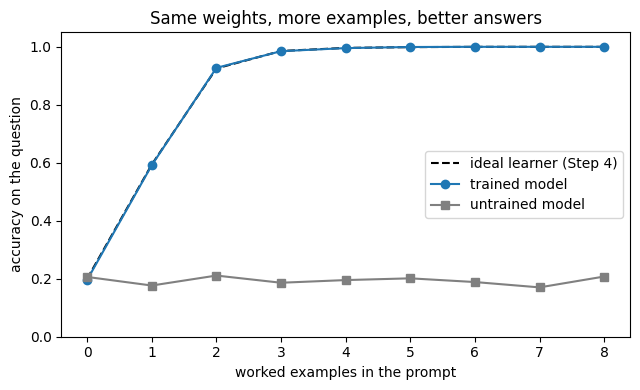

In [9]:
print("examples in the prompt:   ", "      ".join(str(k) for k in SHOW_K))
print("untrained model:          ", row(acc_before))
print("trained model:            ", row(acc_after))
print("ideal learner:            ", row(ideal_acc))
print(f"largest gap between the model and the ideal learner: {np.abs(acc_after - ideal_acc).max():.1%}")

plt.figure(figsize=(6.5, 4))
ks = np.arange(PAIRS)
plt.plot(ks, ideal_acc, "k--", label="ideal learner (Step 4)")
plt.plot(ks, acc_after, "o-", label="trained model")
plt.plot(ks, acc_before, "s-", color="grey", label="untrained model")
plt.xlabel("worked examples in the prompt"); plt.ylabel("accuracy on the question")
plt.ylim(0, 1.05); plt.title("Same weights, more examples, better answers"); plt.legend(); plt.tight_layout(); plt.show()

### Why we see this

The accuracy rises with the number of examples, and it rises along the ideal learner's curve. The weights are
the same for every column: what differs is only what was put in front of the question. That is **in-context
learning**: the forward pass adapts to the examples it is shown.

Note what the model was *not* given: the list of rules, the idea of crossing rules out, or the idea of
"examples". Training on many prompts, each with its own rule, was enough for gradient descent to build a
forward pass that behaves like the ten-line learner of Step 4.

---
## Step 10 - One prompt, close up

`ask()` puts a prompt into the model and returns its five probabilities for the answer. As in Chapter 35, the
model always takes 17 tokens; a shorter prompt goes on the left and the filler to its right is invisible
behind the causal mask.

The hidden rule here is "shift 2". We ask "what does 4 turn into?" three times: with no example, after
`3 → 0`, and after `3 → 0` and `1 → 3`.

> **Predict:** after the single example `3 → 0`, which two answers will share the probability? (Step 2 told
> you which two rules survive. Apply each to 4.)

In [10]:
def ask(m, examples, query):
    """examples = [(x, y), ...]; returns the model's probabilities for f(query)."""
    tokens = [t for pair in examples for t in pair] + [query]
    buf = np.zeros((1, CONTEXT), dtype=np.int32)
    buf[0, :len(tokens)] = tokens                                   # filler to the right is invisible
    logits = m.predict_on_batch(buf)[0, len(tokens) - 1]
    p = np.exp(logits - logits.max())
    return p / p.sum()


examples = [(3, 0), (1, 3)]
close_up = []
for k in range(3):
    p = ask(model, examples[:k], 4)
    close_up.append(p)
    text = " ".join(f"{a}>{b}" for a, b in examples[:k]) + " 4>?"
    print(f"{k} examples | {text:14s} | P(answer = 0..4) = {np.round(p, 2)} | says {p.argmax()}")
print("the right answer under shift 2 is", int(SHIFT[2][4]), "| mirror 3 would say", int(MIRROR[3][4]))

0 examples |  4>?           | P(answer = 0..4) = [0.2  0.2  0.2  0.19 0.2 ] | says 2
1 examples | 3>0 4>?        | P(answer = 0..4) = [0.   0.48 0.   0.   0.51] | says 4
2 examples | 3>0 1>3 4>?    | P(answer = 0..4) = [0. 1. 0. 0. 0.] | says 1
the right answer under shift 2 is 1 | mirror 3 would say 4


### Why we see this

With no example the five answers are equally likely. After `3 → 0` the model puts about half on 1 and half on
4: "shift 2" says 4 → 1 and "mirror 3" says 4 → 4, and the prompt cannot yet say which rule is in force. The
model is not confused. It is correctly uncertain, and its probabilities say so. The second example removes
"mirror 3" and the answer snaps to 1.

This is what a few-shot example does in the lab: it removes rules. Hold on to that picture when you write
prompts for a large model. An example is useful in proportion to the wrong readings of your request that it
rules out.

---
## Step 11 - Nothing was stored

The model has now answered tens of thousands of prompts. Did it learn anything from them, in the sense of
Chapter 1: did any weight change?

We take a fingerprint of all 101,829 weights (a hash of their bytes), answer 20,000 more questions, and take
it again. Then we ask the 0-example question from Step 10 once more, straight after the prompt that taught it
"shift 2".

> **Predict:** will the two fingerprints match? And will the model still know "shift 2" when the examples are
> no longer in the prompt?

In [11]:
def fingerprint(m):
    """A short hash of every weight in the model. Any change to any weight changes it."""
    return hashlib.sha256(b"".join(w.tobytes() for w in m.get_weights())).hexdigest()[:16]


before = fingerprint(model)
x_more, y_more, _ = make_prompts(20_000 // PAIRS + 1, RULES, rng=np.random.default_rng(7))
acc_more = accuracy_by_examples(model, x_more, y_more)
after = fingerprint(model)
print(f"fingerprint before: {before}")
print(f"answered {x_more.shape[0] * PAIRS:,} questions, {acc_more[8]:.1%} right with 8 examples")
print(f"fingerprint after:  {after}   identical: {before == after}")
assert before == after

p_taught = ask(model, [(3, 0), (1, 3)], 4)
p_again = ask(model, [], 4)
print()
print("with the two examples in the prompt:   ", np.round(p_taught, 2))
print("next prompt, the examples left out:    ", np.round(p_again, 2))
print("same as the very first 0-example answer:", bool(np.array_equal(p_again, close_up[0])))

fingerprint before: 83dcf4e4489a3fef
answered 20,007 questions, 100.0% right with 8 examples
fingerprint after:  83dcf4e4489a3fef   identical: True

with the two examples in the prompt:    [0. 1. 0. 0. 0.]
next prompt, the examples left out:     [0.2  0.2  0.2  0.19 0.2 ]
same as the very first 0-example answer: True


### Why we see this

The fingerprints match to the last bit. Answering is a forward pass, and a forward pass reads the weights
without writing them. Whatever the model "learnt" about shift 2 lived in the activations of one forward pass
and was thrown away when that pass ended. Ask again without the examples and the model is back to five equal
guesses, exactly as if the earlier prompt had never happened.

This is true of every deployed language model, whatever its size. When a chat assistant appears to remember
what you said, it is because the application put the earlier turns back into the prompt.

---
## Step 12 - Which examples you choose

Two examples each. In the first set both examples use the **same x** (the second is a repeat). In the second
set the two x values **differ**. Then a test of order: the same four examples, shuffled.

> **Predict:** accuracy for the two sets. (Look back at Step 4: what is a repeated example worth?) And how
> often will reordering four correct examples change the answer?

In [12]:
def ask_many(m, ex_x, ex_y, query):
    """A batch of prompts with k examples each. ex_x, ex_y: (n, k); query: (n,). Returns the argmax answers and probabilities."""
    n, k = ex_x.shape
    buf = np.zeros((n, CONTEXT), dtype=np.int32)
    buf[:, 0:2 * k:2], buf[:, 1:2 * k:2], buf[:, 2 * k] = ex_x, ex_y, query
    logits = m.predict(buf, batch_size=1000, verbose=0)[:, 2 * k]
    p = np.exp(logits - logits.max(axis=-1, keepdims=True))
    p /= p.sum(axis=-1, keepdims=True)
    return p.argmax(axis=-1), p


g = np.random.default_rng(3)
n = 10_000
table = RULES[g.integers(0, len(RULES), size=n)]
query = g.integers(0, N, size=n)
truth = table[np.arange(n), query]
x1 = g.integers(0, N, size=n)
x2 = (x1 + g.integers(1, N, size=n)) % N                           # always different from x1

for name, ex in [("two examples, same x     ", np.stack([x1, x1], axis=1)),
                 ("two examples, different x", np.stack([x1, x2], axis=1))]:
    guess, _ = ask_many(model, ex, np.take_along_axis(table, ex, axis=1), query)
    print(f"{name}: {np.mean(guess == truth):6.1%}")

ex = g.integers(0, N, size=(n, 4))
ey = np.take_along_axis(table, ex, axis=1)
a, _ = ask_many(model, ex, ey, query)
order = np.array([3, 1, 0, 2])
b, _ = ask_many(model, ex[:, order], ey[:, order], query)
print(f"four correct examples, shuffled: the answer changed in {np.mean(a != b):.2%} of {n:,} prompts")

two examples, same x     :  59.9%


two examples, different x: 100.0%


four correct examples, shuffled: the answer changed in 0.00% of 10,000 prompts


### Why we see this

Two examples that repeat one x score what one example scores, 60%. Two examples that differ score 100%. The
prompts are the same length and cost the same. The difference is information: **examples that all look alike
teach less than examples that differ in the way the task needs.** At full size the same thing appears as
few-shot examples that are all of one class, or all easy cases.

Reordering correct examples did nothing here: this model was trained on examples in random order and has
learnt to ignore it. Do not carry that over. Large language models are known to be sensitive to the order of
few-shot examples, because text has order effects that our five symbols do not. The honest lesson is that
order sensitivity is a property of a trained model, to be measured, not assumed.

---
## Step 13 - One wrong example

Now make exactly one example in the prompt wrong: its answer is replaced by a different symbol. The model
never saw a wrong example in training.

> **Predict:** with 2, 4 and 8 examples, how much does one wrong example cost? Does it matter whether the
> wrong one is first or last?

In [13]:
wrong = {}
for k in (2, 4, 8):
    ex = g.integers(0, N, size=(n, k))
    ey = np.take_along_axis(table, ex, axis=1)
    clean, _ = ask_many(model, ex, ey, query)
    wrong[k] = [np.mean(clean == truth)]
    for pos in (0, k - 1):
        bad = ey.copy()
        bad[:, pos] = (bad[:, pos] + g.integers(1, N, size=n)) % N   # any symbol but the right one
        guess, _ = ask_many(model, ex, bad, query)
        wrong[k].append(np.mean(guess == truth))
    print(f"{k} examples | all correct {wrong[k][0]:6.1%} | first one wrong {wrong[k][1]:6.1%} | last one wrong {wrong[k][2]:6.1%}")

2 examples | all correct  91.6% | first one wrong  33.3% | last one wrong  35.4%


4 examples | all correct  99.7% | first one wrong  73.7% | last one wrong  71.9%


8 examples | all correct 100.0% | first one wrong  85.0% | last one wrong 100.0%


### Why we see this

One wrong example in two wrecks the answer: the model has no way to know which of the two to believe, and
often no rule fits both. With more examples the damage shrinks, because the correct ones outvote the wrong
one, but it does not vanish. The last line shows something this particular model picked up: by the eighth
example the rule is always settled, so it has learnt to pay the eighth almost no attention. A wrong first
example hurts; a wrong last one is ignored. Here, then, order *does* matter, although Step 12 found none.
Order sensitivity showed up only when the examples disagreed.

The model treats every example as true. It has no notion of "this one looks like a typo". A prompt is not
checked by the model; whatever you put in it is evidence.

---
## Step 14 - A rule family it never met

So far every test rule came from the two trained families. Now two families the model has never seen:

* **double k:** f(x) = (2x + k) mod 5. Five rules. Just as simple to state as a shift.
* **lookup:** one of the 110 other shuffles of the five symbols. No formula, only a table.

For the lookup tables we also split the questions in two: those whose x **already appeared** in the prompt
with its answer, and those whose x did not.

> **Predict:** accuracy with 8 examples on each family. How confident will the model be? And when the answer
> is written in the prompt, will it copy it?

In [14]:
def family_report(m, tables, seed=2):
    x, y, _ = make_prompts(10_000, tables, rng=np.random.default_rng(seed))
    logits = m.predict(x, batch_size=1000, verbose=0)[:, 0::2]
    p = np.exp(logits - logits.max(axis=-1, keepdims=True))
    p /= p.sum(axis=-1, keepdims=True)
    acc = (p.argmax(axis=-1) == y[:, 0::2]).mean(axis=0)
    return acc, p.max(axis=-1).mean(axis=0), x, y, p.argmax(axis=-1)


family_acc = {}
print("examples in the prompt:   ", "      ".join(str(k) for k in SHOW_K), "   | confidence at 8")
for name, tables in [("shift ", SHIFT), ("mirror", MIRROR), ("double", DOUBLE), ("lookup", LOOKUP)]:
    acc, conf, xf, yf, guess = family_report(model, tables)
    family_acc[name.strip()] = (acc, conf)
    print(f"{name} (trained: {'yes' if name.strip() in ('shift', 'mirror') else 'no '})      {row(acc)}   |  {conf[8]:.0%}")

print()
print("lookup tables, split by whether the question's x already appeared in the prompt with its answer:")
xq, yq = xf[:, 0::2], yf[:, 0::2]
lookup_split = {}
for k in (1, 2, 4, 8):
    seen = (xq[:, :k] == xq[:, k:k + 1]).any(axis=1)
    right = guess[:, k] == yq[:, k]
    lookup_split[k] = (seen.mean(), right[seen].mean(), right[~seen].mean())
    print(f"  {k} examples | answer is in the prompt for {seen.mean():5.1%} of questions: {right[seen].mean():6.1%} right"
          f" | not in the prompt: {right[~seen].mean():6.1%} right")

examples in the prompt:    0      1      2      4      8    | confidence at 8


shift  (trained: yes)       19.6%   63.4%   92.1%   99.6%  100.0%   |  100%


mirror (trained: yes)       19.6%   56.4%   92.1%   99.8%  100.0%   |  100%


double (trained: no )       20.3%   20.3%   25.9%   29.5%   36.5%   |  93%


lookup (trained: no )       20.2%   37.9%   46.5%   53.5%   62.0%   |  95%

lookup tables, split by whether the question's x already appeared in the prompt with its answer:
  1 examples | answer is in the prompt for 20.3% of questions: 100.0% right | not in the prompt:  22.1% right
  2 examples | answer is in the prompt for 36.8% of questions:  84.0% right | not in the prompt:  24.6% right
  4 examples | answer is in the prompt for 59.0% of questions:  74.6% right | not in the prompt:  23.2% right
  8 examples | answer is in the prompt for 83.4% of questions:  70.1% right | not in the prompt:  21.6% right


### Why we see this

On the rules it trained on: 100% with eight examples. On the double family the score creeps from 20% to the
mid-thirties and stops there. More examples do not rescue it, because the model is not short of evidence. It
is short of a procedure. Its forward pass can pick among shifts and mirrors; it has no machinery for
"twice x".

Look at the confidence column. On the families it cannot do, the model is about as sure of itself as on the
ones it can. It forces the examples onto the nearest rule it knows and answers from that rule. Nothing in its
output says "this prompt is outside what I can do".

The lookup split is the sharpest result in the lab. When the question's x has already appeared in the prompt,
the answer is sitting there in plain sight, one token to the right of it. With one example the model gets it
right (one pair always fits some trained rule). With eight examples it gets the visible answer wrong about
three times in ten. It never learnt to *look things up*, because during training, working out the rule was
always enough. **In-context learning is not reading. A model uses its context through the procedures that
training built, and only through those.**

---
## Step 15 - A new member of a known family

A harder question. Is the model working out the rule, or recognising which of ten rules it has met? To
find out, train a second, identical model on only **eight** of the ten rules, leaving out "shift 3" and
"mirror 1", and then test it on those two.

> **Predict:** accuracy with 8 examples on the two rules it never trained on: near 100% (it has learnt what
> a shift is), near 20% (it knows only its eight rules), or in between?

> This cell trains a model: about half a minute.

In [15]:
HELD_OUT = [3, 6]                                                   # shift 3 and mirror 1
kept = [i for i in range(len(RULES)) if i not in HELD_OUT]
print("left out of training:", [RULE_NAMES[i] for i in HELD_OUT])

keras.utils.set_random_seed(SEED + 1)
model8 = build_tinygpt(N, context=CONTEXT)
x_held, y_held, _ = make_prompts(5000, RULES[HELD_OUT], rng=np.random.default_rng(11))
x_kept, y_kept, _ = make_prompts(5000, RULES[kept], rng=np.random.default_rng(12))
_ = train(model8, RULES[kept], 600, rounds=[200, 400], test=(x_held, y_held), label="held-out rules | ")
acc_kept = accuracy_by_examples(model8, x_kept, y_kept)
acc_held = accuracy_by_examples(model8, x_held, y_held)
print()
print("examples in the prompt:      ", "      ".join(str(k) for k in SHOW_K))
print("the 8 rules it trained on:   ", row(acc_kept))
print("the 2 rules it never met:    ", row(acc_held))

left out of training: ['shift 3', 'mirror 1']


held-out rules | step   200  loss 1.001  accuracy at 0/1/2/4/8 examples:   0.0%   20.6%   19.5%   19.8%   18.3%  [ 13s]


held-out rules | step   600  loss 0.246  accuracy at 0/1/2/4/8 examples:   0.0%   20.6%   20.8%   20.1%   18.7%  [ 26s]



examples in the prompt:       0      1      2      4      8
the 8 rules it trained on:     24.2%   69.0%   93.6%   99.8%   99.8%
the 2 rules it never met:       0.0%   20.6%   20.8%   20.1%   18.7%


### Why we see this

On its eight rules the second model is as good as the first. On the two it never met, eight examples leave it
at about the 20% of a blind guess. It has not learnt "what a shift is". With so few rules to train on, what
the model built is "which of my eight rules is this?", not "what is the rule?". (Its 0-example score on the
held-out rules is 0% for the same reason: it has learnt which answers are common under its eight rules, and
the held-out rules give exactly the uncommon ones.)

This number is not stable. While this lab was being written, the same experiment with another seed and 1,000
steps scored about 50% on the held-out rules. Neither run came anywhere near the 100% of the trained rules,
and that is the finding to keep: one run of a small model is an anecdote (Chapter 39 made the same point).

Two things would move this towards real generalisation: many more rules in training, and a family too large
to memorise. That is the situation of a large language model, which meets an enormous variety of tasks in its
training text. Research on small transformers trained on families of functions has reported the same
pattern: with few training tasks the model recognises them, with many it starts to solve new ones. How far
large models do one or the other on a given prompt is an open research question.

---
## Step 16 - The other way to learn: change the weights

The first model cannot do the double family from examples. It can from **training**. We copy the model, train
the copy for 300 steps on double-rule prompts (fine-tuning, Chapter 39), and compare the two kinds of
learning.

> **Predict:** after fine-tuning, (1) accuracy on double rules, (2) whether the fingerprint changed, and
> (3) what happened to shift and mirror, which the fine-tuning data did not contain.

In [16]:
tuned = build_tinygpt(N, context=CONTEXT)
tuned.set_weights(model.get_weights())
print("copy made. fingerprint equals the original:", fingerprint(tuned) == fingerprint(model))

x_dbl, y_dbl, _ = make_prompts(5000, DOUBLE, rng=np.random.default_rng(13))
_ = train(tuned, DOUBLE, 300, rounds=[100, 200], peak_lr=1e-3, test=(x_dbl, y_dbl), label="fine-tune on double | ")
print()
print("fingerprint of the tuned copy equals the original:", fingerprint(tuned) == fingerprint(model))
print()
print("examples in the prompt:        ", "      ".join(str(k) for k in SHOW_K))
tuned_acc = {}
for name, tables in [("shift ", SHIFT), ("mirror", MIRROR), ("double", DOUBLE)]:
    tuned_acc[name.strip()] = family_report(tuned, tables)[0]
    print(f"{name}  original model       {row(family_acc[name.strip()][0])}")
    print(f"{name}  after fine-tuning    {row(tuned_acc[name.strip()])}")

copy made. fingerprint equals the original: True


fine-tune on double | step   100  loss 1.695  accuracy at 0/1/2/4/8 examples:  19.8%   43.3%   67.7%   84.7%   93.5%  [ 10s]


fine-tune on double | step   300  loss 0.268  accuracy at 0/1/2/4/8 examples:  20.3%   98.5%   99.5%   99.9%   99.9%  [ 17s]

fingerprint of the tuned copy equals the original: False

examples in the prompt:         0      1      2      4      8


shift   original model        19.6%   63.4%   92.1%   99.6%  100.0%
shift   after fine-tuning     20.4%   20.3%   38.1%   61.4%   81.1%


mirror  original model        19.6%   56.4%   92.1%   99.8%  100.0%
mirror  after fine-tuning     18.9%   20.3%   38.2%   60.6%   79.4%


double  original model        20.3%   20.3%   25.9%   29.5%   36.5%
double  after fine-tuning     19.6%   98.5%   99.4%   99.9%   99.9%


### Why we see this

Three hundred steps of training did what no number of examples in the prompt could: the copy now handles the
double family. The price is on the next lines. The fingerprint has changed, so this is a different model, and
it has lost ground on shift and mirror, which its fine-tuning data never mentioned: with one example it is
back to a blind guess, and with eight it is well short of the 100% it had (the forgetting of Chapter 39).

| | learning in the context | learning in the weights |
|---|---|---|
| what changes | activations, for one forward pass | the weights, for good |
| cost | a longer prompt on every call | a training run, once |
| lasts | until the prompt ends | until the next training run |
| can it add a new procedure? | no: it selects among what training built | yes |
| can it break what was there? | no | yes |

---
## Step 17 - What a prompt costs, and what changes at full size

Examples are not free. They sit in the window on every call, and the window is finite.

> **Predict:** our window is 17 tokens. What is the largest number of examples a prompt can hold? And if an
> 8-example prompt answers one question, how many tokens does the model read per answer, against a 0-example
> prompt?

In [17]:
print("window T =", CONTEXT, "tokens -> at most", (CONTEXT - 1) // 2, "examples and one question")
for k in SHOW_K:
    print(f"  {k} examples: the model reads {2 * k + 1:2d} tokens to produce 1 answer  (accuracy {acc_after[k]:6.1%})")

# the same arithmetic at a realistic size (made-up but typical lengths; no prices, they date)
instruction, per_example, user_input, n_examples, calls = 200, 150, 300, 20, 100_000
per_call = instruction + n_examples * per_example + user_input
print()
print(f"a real few-shot prompt: {instruction} + {n_examples} x {per_example} + {user_input} = {per_call:,} tokens per call")
print(f"over {calls:,} calls: {per_call * calls:,} tokens read, of which {n_examples * per_example * calls:,} are the same examples again")
print(f"share of every call that is repeated examples: {n_examples * per_example / per_call:.0%}")
print(f"\nwhole notebook: {time.time() - t_start:.0f} s")

window T = 17 tokens -> at most 8 examples and one question
  0 examples: the model reads  1 tokens to produce 1 answer  (accuracy  19.6%)
  1 examples: the model reads  3 tokens to produce 1 answer  (accuracy  59.2%)
  2 examples: the model reads  5 tokens to produce 1 answer  (accuracy  92.7%)
  4 examples: the model reads  9 tokens to produce 1 answer  (accuracy  99.6%)
  8 examples: the model reads 17 tokens to produce 1 answer  (accuracy 100.0%)

a real few-shot prompt: 200 + 20 x 150 + 300 = 3,500 tokens per call
over 100,000 calls: 350,000,000 tokens read, of which 300,000,000 are the same examples again
share of every call that is repeated examples: 86%

whole notebook: 104 s


### Why we see this

In-context learning is paid for on every call. The examples are re-read each time, because nothing was kept
from the last call (Step 11). That is the trade against fine-tuning in one line: a prompt costs per call and
changes in a minute; a fine-tune costs once and changes in a training run.

**What this lab is, and is not.**

| | in our lab | in the real thing |
|---|---|---|
| model | 101,829 parameters, 2 blocks | billions of parameters, dozens of blocks |
| what training showed it | 10 rules on 5 symbols | a large share of the written internet |
| a prompt | 17 symbols | thousands to hundreds of thousands of tokens |
| an instruction ("add two") | impossible: it has no words | works, because the words were learnt in pretraining |
| what examples do | select one of 10 known rules | select, combine and adapt among a vast range of learnt behaviours |
| new rule family | fails, confidently | often works, when the family resembles something in pretraining; fails, often confidently, when it does not |

The mechanism is the same: weights fixed, behaviour set by the context. The reach is not comparable.

---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 8: `rounds=[50] * 20` and plot accuracy at 8 examples against the step | At which step does the jump happen? Is it the same with `SEED = 7`? | |
| 2 | Step 8: train on `SHIFT` only | What does the ideal learner score with 1 example now? Does the model match it? | |
| 3 | Step 8: train on `np.concatenate([RULES, DOUBLE])` | Ideal accuracy with 1 example (three rules survive)? Does Step 14's double row recover? | |
| 4 | Step 6: `build_tinygpt(N, context=CONTEXT, blocks=1)` | Can one block do it? If it stalls, at what accuracy, and what would that accuracy mean? | |
| 5 | Step 2: `N = 7` (and raise `STEPS` to 3000 or more) | How long is the plateau now? Be ready for it not to finish. | |
| 6 | Step 3: `PAIRS = 5` | New `CONTEXT`? New parameter count (hand formula first)? | |
| 7 | Step 13: make two of eight examples wrong | Does accuracy fall by twice as much? | |
| 8 | Step 16: fine-tune on `np.concatenate([RULES, DOUBLE])` instead of `DOUBLE` | Is shift and mirror still lost? | |

---
## Exercises

1. **An instruction token.** Add ten extra symbols to the vocabulary, one naming each rule, and put the right
   one at the start of half the training prompts. Test with the name and no examples (zero-shot), with
   examples and no name (few-shot), and with a name that contradicts the examples. Which does the model
   believe?
2. **Teach it to look things up.** Train on lookup tables only (a fresh shuffle for every sequence). Draw the
   ideal learner's curve first: it needs the question's x to have appeared. Does the model reach it in 1,000
   steps? In 5,000? Then test that model on a prompt whose examples follow "shift 2" and whose question is an
   unseen x.
3. **Noise in training.** Train with one example in ten corrupted. Repeat Step 13. Has the model learnt to
   outvote a wrong example?
4. **Where does it look?** Build a second Keras model that returns the attention scores of block 2
   (`return_attention_scores=True`) for one prompt. At the question position, which earlier positions get the
   weight: the x tokens, the answers, or both?
5. **Rehearsal.** Repeat Step 16 with a batch that is half double rules and half shift and mirror rules.
   Compare forgetting with Step 16 and connect it to the cures listed in Chapter 39.
6. **How many rules before it generalises?** Use all affine rules f(x) = (a·x + k) mod 5 with a from 1 to 4:
   twenty rules. Hold out four, train on sixteen, and repeat Step 15. Is the held-out accuracy higher than
   with eight training rules?

---
## Cheat sheet

| Fact | Value / rule |
|---|---|
| The task | `x1 f(x1) ... xq ?` with f drawn fresh for every prompt and never named |
| The model | TinyGPT blocks, V = 5, T = 17: 5·64 + 17·64 + 2·49,984 + 128 + 325 = 101,829 parameters |
| Training signal | next-token loss on the answer positions only (`sample_weight` 1 on even positions) |
| Ideal learner | cross out rules that disagree with an example: 20%, 60%, 92%, 98.4%, ... = 1 − 0.4 · 0.2^(k − 1) |
| In-context learning | accuracy rises with the examples in the prompt while every weight stays the same |
| Proof nothing is stored | hash of all weights before and after answering: identical |
| Between prompts | nothing carries over; an assistant "remembers" only what is put back in the prompt |
| Example choice | two examples that repeat one x are worth one; two that differ settle the rule |
| A wrong example | is believed like any other; more correct examples dilute it, they do not remove it |
| Outside the trained families | near-chance accuracy, high confidence, and no use of answers visible in the prompt |
| New member of a known family | in between: with few training rules the model mostly recognises |
| Fine-tuning instead | adds the new procedure, changes the weights, and can forget the old families |
| Cost | examples are re-read on every call; the window caps how many fit |